# 03 · Labels, candidate generation and features

**Input:** cleaned trips in `data/processed/` (run `scripts/run_cleaning.py` first).
**Output:** `data/features/<partition>.parquet` (one row per GPS fix × candidate arc),
`data/features/<partition>_fixes.parquet` (one row per fix), and `outputs/features/` (report, sweep, figures).

The code lives in `src/pathsnap/` so the FastAPI backend can reuse exactly the same functions:

| module | job | uses the route? |
|---|---|---|
| `labels.py` | which arc each fix was really on (the training target) | **yes**: training and scoring only |
| `candidates.py` | which arcs each fix *could* be on | no |
| `features.py` | numbers describing how well each candidate fits | no |

This notebook runs them on `train` and `student_test`. The evaluator-test partition is not on disk and is never used.

In [1]:
import json, sys, time
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from pathsnap import candidates as CND, features as F, labels as L
from pathsnap.cleaning import PROCESSED_ROOT, load_clean_trip

FEAT_ROOT, OUT = ROOT / "data" / "features", ROOT / "outputs" / "features"
FIG = OUT / "figures"
for d in (FEAT_ROOT, OUT, FIG):
    d.mkdir(parents=True, exist_ok=True)

C_POS, C_NEG, C_GPS, C_GRID = "#2a78d6", "#eb6834", "#1baf7a", "#d9d8d2"   # fixed colour order
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": C_GRID, "grid.linewidth": 0.6, "figure.dpi": 110})
TRAIN_TRIPS = sorted(t.name for t in (PROCESSED_ROOT / "train").iterdir())
TEST_TRIPS = sorted(t.name for t in (PROCESSED_ROOT / "student_test").iterdir())
print(len(TRAIN_TRIPS), "train trips,", len(TEST_TRIPS), "student_test trips")

80 train trips, 10 student_test trips


## 1. Per-fix labels (`labels.py`)

`.route` is the ordered list of arcs the car drove. It does **not** say which GPS fix was on which arc.
"Label = nearest route arc" fails in two places:
* **U-turns:** the reverse arc of the same street is just as near;
* **revisits:** the same arc appears twice in the route, and we need to know which visit a fix belongs to.

**Order-respecting alignment (dynamic programming, a Viterbi over route positions):**
* the state of fix *i* is a route **position** *k_i* (an index into the route list), so the two visits of a
  revisited arc are different states;
* only positions whose arc is within `ALIGN_RADIUS_M = 100 m` of the fix are considered;
* cost = distance from the fix to that arc;
* moving forward along the route (or staying) is free, and moving backward costs `ALIGN_BACK_PENALTY_M = 300 m`.
  The route has 14 known breaks, so backward moves are allowed, but only when the alternative is far worse;
* the cheapest total path is recovered by backtracking, and label = canonical arc at the chosen position.

Fixes with no route arc within 100 m get no label (`-1`).

In [2]:
c = load_clean_trip("train", "00000013")
true_arc = L.align_labels(c["track"], c["nodes"], c["arcs"], c["route"])
print(f"train 00000013: {(true_arc >= 0).mean():.1%} of fixes labelled, "
      f"{len(set(true_arc[true_arc >= 0]))} distinct arcs used out of {c['route']['canonical_arc_id'].nunique()} in the route")

train 00000013: 100.0% of fixes labelled, 705 distinct arcs used out of 788 in the route


The label counts for every trip are in section 4.

## 2. Candidate generation (`candidates.py`): choosing radius and K on train only

A spatial index (shapely STRtree) is built per trip over the candidate arcs. Zero-length arcs and geometric duplicates
are skipped, and labels are compared on canonical ids. For each fix we keep the arcs within radius **R**, at most the **K**
nearest. A fix with nothing in range gets its single nearest arc (`is_fallback`), so every fix still gets a prediction.

**Candidate miss rate** = share of fixes whose true arc is **not** in the candidate set. Those fixes are lost for good:
no model or HMM can recover them. A bigger set lowers the miss rate, but adds negatives and slows everything down.

We query once with the widest radius and work out every (R, K) setting from that query. The sweep uses only
**train** trips and their `label_reliable` fixes.

**Selection rule, fixed before looking at the results:** take the setting with the **smallest mean candidate set**
whose miss rate is within **0.1 percentage points** of the best miss rate in the grid.

In [3]:
RADII, KS = (25, 50, 75, 100, 150), (4, 6, 8, 12, 16, 24)
t0 = time.perf_counter()
with ProcessPoolExecutor() as ex:
    sw = [r for res in ex.map(F.sweep_trip, [("train", t, RADII, KS) for t in TRAIN_TRIPS]) for r in res]
sweep = pd.DataFrame(sw).groupby(["radius_m", "k"])[["fixes", "missed", "cands"]].sum().reset_index()
sweep["miss_rate_pct"] = 100 * sweep.missed / sweep.fixes
sweep["cands_per_fix"] = sweep.cands / sweep.fixes
sweep.to_csv(OUT / "candidate_sweep.csv", index=False)
print(f"sweep over {len(TRAIN_TRIPS)} train trips in {time.perf_counter() - t0:.0f} s")
sweep.pivot(index="radius_m", columns="k", values="miss_rate_pct").round(3)

sweep over 80 train trips in 8 s


k,4,6,8,12,16,24
radius_m,,,,,,
25,3.066,1.748,1.369,1.158,1.101,1.032
50,2.399,0.963,0.474,0.192,0.111,0.033
75,2.395,0.959,0.469,0.188,0.104,0.027
100,2.395,0.959,0.469,0.188,0.104,0.027
150,2.395,0.959,0.469,0.188,0.104,0.027


In [4]:
sweep.pivot(index="radius_m", columns="k", values="cands_per_fix").round(2)

k,4,6,8,12,16,24
radius_m,,,,,,
25,3.08,3.75,4.15,4.54,4.70,4.80
50,3.54,4.74,5.69,7.03,7.91,8.86
75,3.70,5.14,6.39,8.41,9.97,12.14
100,3.79,5.37,6.79,9.23,11.27,14.47
150,3.87,5.60,7.22,10.15,12.78,17.33


In [5]:
best = sweep.miss_rate_pct.min()
ok = sweep[sweep.miss_rate_pct <= best + 0.1].sort_values("cands_per_fix")
chosen = ok.iloc[0]
print(f"best miss rate in grid: {best:.3f}%  ->  chosen R = {chosen.radius_m:g} m, K = {chosen.k:g} "
      f"(miss {chosen.miss_rate_pct:.3f}%, {chosen.cands_per_fix:.2f} candidates/fix)")
# the module defaults are what the API will use, so they must match the sweep's choice
assert (CND.CAND_RADIUS_M, CND.MAX_CANDS) == (chosen.radius_m, chosen.k), "update candidates.py constants"
cand_cfg = {"CAND_RADIUS_M": CND.CAND_RADIUS_M, "MAX_CANDS": CND.MAX_CANDS,
            "rule": "smallest mean candidate set with train miss rate within 0.1 pp of the grid best",
            "train_miss_rate_pct": round(float(chosen.miss_rate_pct), 4),
            "cands_per_fix": round(float(chosen.cands_per_fix), 3)}
(OUT / "candidate_config.json").write_text(json.dumps(cand_cfg, indent=1))

best miss rate in grid: 0.027%  ->  chosen R = 50 m, K = 16 (miss 0.111%, 7.91 candidates/fix)


193

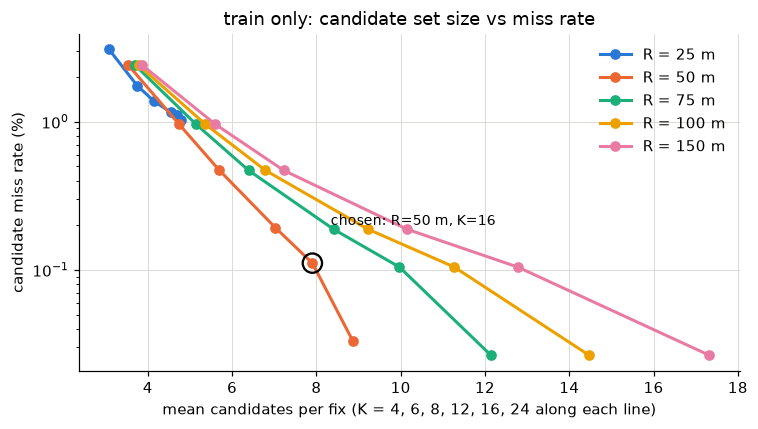

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
for col, (R, g) in zip(colors, sweep.groupby("radius_m")):
    ax.plot(g.cands_per_fix, g.miss_rate_pct, "-o", color=col, lw=2, ms=6, label=f"R = {R} m")
ax.scatter([chosen.cands_per_fix], [chosen.miss_rate_pct], s=160, facecolor="none", edgecolor="black", lw=1.5, zorder=4)
ax.annotate(f"chosen: R={chosen.radius_m:g} m, K={chosen.k:g}", (chosen.cands_per_fix, chosen.miss_rate_pct),
            xytext=(12, 25), textcoords="offset points", fontsize=9)
ax.set_xlabel("mean candidates per fix (K = 4, 6, 8, 12, 16, 24 along each line)")
ax.set_ylabel("candidate miss rate (%)"); ax.set_yscale("log")
ax.set_title("train only: candidate set size vs miss rate"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "00_candidate_sweep.png"); plt.show()

Beyond 50 m the radius barely changes the miss rate (the lines for 50–150 m overlap). The true arc is almost always
close, and the misses come from K being too small where many roads crowd together. So R = 50 m with a generous K is
the cheapest setting that still keeps nearly every true arc.

## 3. Features (`features.py`)
One row per (fix, candidate) pair. No feature uses the route, absolute coordinates, timestamps or ids.

| group | features | why |
|---|---|---|
| geometry | `dist_m`, `dist_rank`, `dist_minus_min`, `dist_ratio`, `n_cands`, `is_fallback`, `proj_t`, `off_end_m`, `arc_length_m` | the closer arc is usually right; rank and gap to the best candidate make the distance relative to the fix's other candidates |
| direction | `heading_diff_deg`, `heading_cos`, `heading_disp_m` | a two-way road is **two arcs at the same distance**, and only the movement direction separates them. `heading_disp_m` says how far the car moved over 4 s; when it is small, the heading is noise |
| temporal consistency | `d_prev_m`, `d_next_m`, `d_win_mean_m`, `d_win_max_m`, `win_mean_rank`, `win_mean_minus_min` | the true arc stays close for several fixes in a row; a parallel road that one noisy fix drifts onto does not |
| motion / fix quality | `speed_med_mps`, `dt_prev_s`, `is_stop`, `is_fast_step`, `is_off_network` | a rolling median of speed, because raw speed has fast-step runs (EDA); when the car is stopped or off the network, distance and heading mean less |
| topology | `is_two_way`, `from_in_deg`, `to_out_deg`, `in_largest_scc` | intersections, one-way roads and disconnected pieces behave differently |

The context windows never cross a long GPS gap (`segment_id`). **Target:** `label = 1` if the candidate is the fix's
true canonical arc, else 0. Scalers are **not** fitted here; that happens inside each CV training fold (notebook 04).

In [7]:
rows, fixes = F.build_trip_features(c)
rows[["fix_idx", "arc_id", "label"] + F.FEATURE_COLS].head(8)

,fix_idx,arc_id,label,dist_m,dist_rank,dist_minus_min,dist_ratio,n_cands,is_fallback,proj_t,...,win_mean_minus_min,speed_med_mps,dt_prev_s,is_stop,is_fast_step,is_off_network,is_two_way,from_in_deg,to_out_deg,in_largest_scc
0,0,7254,1,2.993666,0,0.000000,1.000000,6,False,0.045596,...,0.000000,3.022377,1.0,False,False,False,True,2,2,True
1,0,7257,0,2.993666,1,0.000000,1.000000,6,False,0.954404,...,0.000000,3.022377,1.0,False,False,False,True,2,2,True
2,0,7252,0,3.864829,2,0.871163,1.218136,6,False,1.000000,...,4.837045,3.022377,1.0,False,False,False,True,2,2,True
3,0,7255,0,3.864829,3,0.871163,1.218136,6,False,0.000000,...,4.837045,3.022377,1.0,False,False,False,True,2,2,True
4,0,12813,0,35.818632,4,32.824965,9.219256,6,False,1.000000,...,35.549546,3.022377,1.0,False,False,False,True,2,1,True
5,0,12826,0,35.818632,5,32.824965,9.219256,6,False,0.000000,...,35.549546,3.022377,1.0,False,False,False,True,1,2,True
6,1,7254,1,1.217535,0,0.000000,1.000000,6,False,0.028860,...,0.000000,4.207993,1.0,False,False,False,True,2,2,True
7,1,7257,0,1.217535,1,0.000000,1.000000,6,False,0.971140,...,0.000000,4.207993,1.0,False,False,False,True,2,2,True


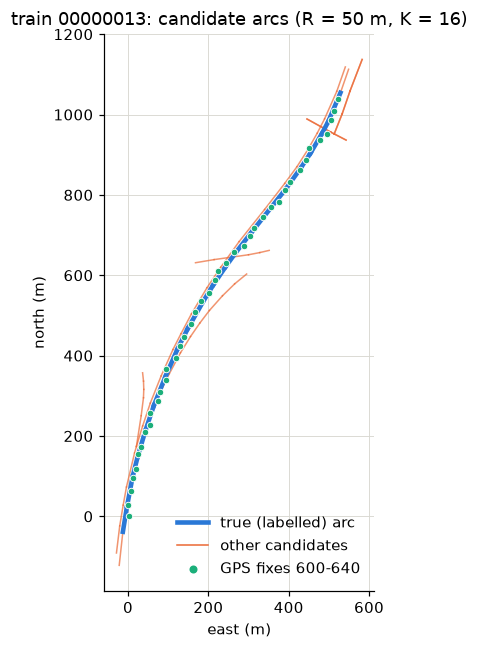

In [8]:
nxy = c["nodes"][["x", "y"]].to_numpy()
fr, to = c["arcs"]["from_node"].to_numpy(), c["arcs"]["to_node"].to_numpy()
win = rows[rows.fix_idx.between(600, 640)]
tr = c["track"].iloc[600:641]
x0, y0 = tr.x.min(), tr.y.min()
fig, ax = plt.subplots(figsize=(6, 6))
for a in win.loc[win.label == 0, "arc_id"].unique():
    ax.plot(nxy[[fr[a], to[a]], 0] - x0, nxy[[fr[a], to[a]], 1] - y0, color=C_NEG, lw=1, alpha=0.7)
for a in win.loc[win.label == 1, "arc_id"].unique():
    ax.plot(nxy[[fr[a], to[a]], 0] - x0, nxy[[fr[a], to[a]], 1] - y0, color=C_POS, lw=3)
ax.scatter(tr.x - x0, tr.y - y0, s=18, color=C_GPS, zorder=3, edgecolor="white", linewidth=0.6)
ax.plot([], [], color=C_POS, lw=3, label="true (labelled) arc")
ax.plot([], [], color=C_NEG, lw=1, label="other candidates")
ax.scatter([], [], s=18, color=C_GPS, label="GPS fixes 600-640")
ax.set_aspect("equal"); ax.set_xlabel("east (m)"); ax.set_ylabel("north (m)")
ax.set_title("train 00000013: candidate arcs (R = 50 m, K = 16)"); ax.legend(loc="lower right", frameon=False)
fig.tight_layout(); fig.savefig(FIG / "01_candidates_example.png"); plt.show()

## 4. Run every trip (train + student_test)

In [9]:
jobs = [("train", t) for t in TRAIN_TRIPS] + [("student_test", t) for t in TEST_TRIPS]
t0 = time.perf_counter()
res = {"train": ([], []), "student_test": ([], [])}
summ = []
with ProcessPoolExecutor() as ex:
    for part, r, f, s in ex.map(F.process_trip, jobs):
        res[part][0].append(r); res[part][1].append(f); summ.append(s)
rows_all = {p: pd.concat(r, ignore_index=True) for p, (r, _) in res.items()}
fixes_all = {p: pd.concat(f, ignore_index=True) for p, (_, f) in res.items()}
for p in rows_all:
    rows_all[p].to_parquet(FEAT_ROOT / f"{p}.parquet", index=False)
    fixes_all[p].to_parquet(FEAT_ROOT / f"{p}_fixes.parquet", index=False)
summary = pd.DataFrame(summ)
summary.to_csv(OUT / "feature_summary.csv", index=False)
print(f"{len(jobs)} trips in {time.perf_counter() - t0:.0f} s")

90 trips in 12 s


In [10]:
tab = []
for p in rows_all:
    r, f = rows_all[p], fixes_all[p]
    rel = f[f.label_reliable]
    tab.append({"partition": p, "trips": f.trip_id.nunique(), "fixes": len(f),
                "labelled fixes": int(f.has_label.sum()), "labelled %": round(100 * f.has_label.mean(), 2),
                "reliable fixes": len(rel), "candidate rows": len(r),
                "cands/fix": round(len(r) / len(f), 2), "positive rows %": round(100 * r.label.mean(), 2),
                "miss rate % (reliable)": round(100 * (1 - rel.true_in_cands.mean()), 3),
                "miss rate % (labelled)": round(100 * (1 - f[f.has_label].true_in_cands.mean()), 3),
                "nearest-arc Top-1 % (reliable)": round(100 * rel.nearest_is_true.mean(), 2)})
part_tab = pd.DataFrame(tab).set_index("partition")
part_tab.T

partition,train,student_test
trips,80.000,10.000
fixes,208417.000,19160.000
labelled fixes,188425.000,19157.000
labelled %,90.410,99.980
reliable fixes,180978.000,19133.000
candidate rows,1530256.000,169234.000
cands/fix,7.340,8.830
positive rows %,12.120,11.300
miss rate % (reliable),0.111,0.031
miss rate % (labelled),1.578,0.157


**Nearest-arc Top-1** is the no-model baseline: always pick the closest candidate. It is only about 50 %, because on a
two-way street the two directions are equally close, so the nearest arc is a coin flip. The models must beat this.

In [11]:
worst = summary.sort_values("miss_rate_reliable", ascending=False).head(8)
worst[["partition", "trip_id", "n_fixes", "frac_labelled", "frac_reliable", "miss_rate_reliable", "nearest_acc_reliable"]]

,partition,trip_id,n_fixes,frac_labelled,frac_reliable,miss_rate_reliable,nearest_acc_reliable
58,train,00000072,969,1.000000,1.000000,0.092879,0.341589
49,train,00000061,1430,1.000000,0.995105,0.043570,0.272663
74,train,00000093,1211,1.000000,0.993394,0.020781,0.543641
3,train,00000004,1064,1.000000,1.000000,0.001880,0.445489
72,train,00000090,536,1.000000,1.000000,0.001866,0.559701
47,train,00000058,599,1.000000,1.000000,0.001669,0.572621
64,train,00000081,3224,0.995968,0.968983,0.001601,0.731434
55,train,00000069,2067,1.000000,1.000000,0.001451,0.474117


## 5. Do the features separate true arcs from wrong ones? (train rows used for training)

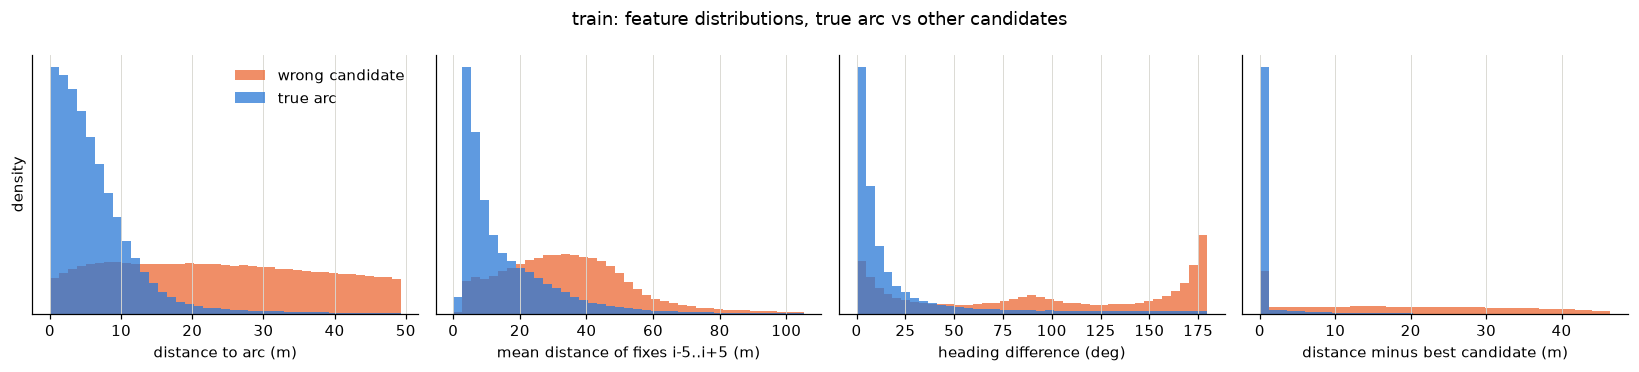

In [12]:
tr_rows = rows_all["train"]
tr_rows = tr_rows[tr_rows.label_reliable & ~tr_rows.exclude_trip]
show = [("dist_m", "distance to arc (m)"), ("d_win_mean_m", "mean distance of fixes i-5..i+5 (m)"),
        ("heading_diff_deg", "heading difference (deg)"), ("dist_minus_min", "distance minus best candidate (m)")]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (col, lab) in zip(axes, show):
    bins = np.linspace(0, tr_rows[col].quantile(0.99), 40)
    ax.hist(tr_rows.loc[tr_rows.label == 0, col], bins=bins, density=True, color=C_NEG, alpha=0.75, label="wrong candidate")
    ax.hist(tr_rows.loc[tr_rows.label == 1, col], bins=bins, density=True, color=C_POS, alpha=0.75, label="true arc")
    ax.set_xlabel(lab); ax.set_yticks([])
axes[0].set_ylabel("density"); axes[0].legend(frameon=False)
fig.suptitle("train: feature distributions, true arc vs other candidates")
fig.tight_layout(); fig.savefig(FIG / "02_feature_separation.png"); plt.show()

For wrong candidates the heading difference has a peak near 180°: that is the opposite-direction arc of the same
street. Distance cannot separate it from the true arc, but heading can.

## 6. Save the report

In [13]:
Lr = ["# PathSnap: Labels, Candidates and Features", "", "Auto-generated by `notebooks/03_features.ipynb`.", "",
      "## Candidate setting (chosen on train only)", "", "```json", json.dumps(cand_cfg, indent=1), "```", "",
      "Miss rate (%) by radius (rows) and K (columns), train label-reliable fixes:", "",
      sweep.pivot(index="radius_m", columns="k", values="miss_rate_pct").round(3).to_markdown(), "",
      "Mean candidates per fix:", "",
      sweep.pivot(index="radius_m", columns="k", values="cands_per_fix").round(2).to_markdown(), "",
      "## Per partition (chosen setting)", "", part_tab.T.to_markdown(), "",
      "## Highest candidate miss rates", "",
      worst[["partition", "trip_id", "n_fixes", "frac_labelled", "frac_reliable", "miss_rate_reliable", "nearest_acc_reliable"]].to_markdown(index=False),
      "", "## Columns", "",
      f"* Keys: `{', '.join(F.KEY_COLS)}`. `trip_id` is the group for GroupKFold.",
      f"* Model inputs (`FEATURE_COLS`, {len(F.FEATURE_COLS)}): `{', '.join(F.FEATURE_COLS)}`.",
      f"* Route-based, never inputs (`LABEL_COLS`): `{', '.join(F.LABEL_COLS)}`.",
      "* Training rows: `label_reliable & ~exclude_trip`.", "",
      "![sweep](figures/00_candidate_sweep.png)", "![candidates](figures/01_candidates_example.png)",
      "![features](figures/02_feature_separation.png)"]
(OUT / "FEATURES_REPORT.md").write_text("\n".join(Lr) + "\n", encoding="utf-8")
print("wrote", OUT / "FEATURES_REPORT.md")

wrote C:\College\sem-v\ml\ml_hackathon\PATHSNAP\outputs\features\FEATURES_REPORT.md
